Pada tahap magang sebelumnya, telah dilakukan eksperimen menggunakan dataset NOAA sebagai data pengganti sementara (stand-in), mengingat data resmi dari BMKG belum tersedia saat itu. Notebook ini melanjutkan proses tersebut dengan menggunakan data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari–Juni 2025, yang menjadi data utama untuk penerapan model prediksi visibility pada laporan magang ini.

# 1. Data Loading and Inspection

Data yang digunakan pada tahap ini bersumber dari data observasi resmi Stasiun Meteorologi Sultan Thaha Jambi periode Januari-Juni 2025. Berbeda dengan dataset NOAA yang digunakan sebelumnya, data ini sudah tersedia dalam bentuk tabel dengan variabel yang terpisah per kolom, sehingga tidak diperlukan proses penguraian (parsing) nilai gabungan seperti pada tahap sebelumnya. Tahap ini bertujuan untuk memahami struktur data secara umum sebelum dilakukan proses pre-processing lebih lanjut. Kita belum memodifikasi bentuk data dan hanya ingin mengetahui jumlah baris dan kolom yang tersedia, jenis serta satuan dari masing-masing variabel, keberadaan missing value, dan bagaimana pola interval waktu pencatatannya (mengingat data seharusnya tercatat per jam, apakah terdapat lompatan waktu atau duplikasi timestamp).

## 1.1 Import Libraries

In [259]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, make_scorer, ConfusionMatrixDisplay, precision_recall_fscore_support
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

## 1.2 Load Dataset

Path dataset disesuaikan dengan lokasi penyimpanan pada perangkat

In [260]:
data_df = pd.read_csv('visibility-dataset/bmkg-jambi-26.csv')
data_df.head(5)

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_low_cover_2,cloud_low_cover_3,cloud_low_cover_1,cloud_cover_oktas_m,rainfall_24h_rrrr,created_at,updated_at,qc_flag,qc_histories,observer_name
0,Stasiun Meteorologi Sultan Thaha,2026-01-01 00:00:00,130,2,1006.0,1009.1,23.6,23.2,23.3,98,...,NaN,NaN,4,8,12.0,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Mustar Puad
1,Stasiun Meteorologi Sultan Thaha,2026-01-01 01:00:00,120,4,1007.2,1010.1,24.0,23.3,23.5,96,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
2,Stasiun Meteorologi Sultan Thaha,2026-01-01 02:00:00,310,5,1007.6,1010.6,25.0,23.2,23.7,90,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
3,Stasiun Meteorologi Sultan Thaha,2026-01-01 03:00:00,300,5,1007.9,1010.9,26.0,23.5,24.2,86,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
4,Stasiun Meteorologi Sultan Thaha,2026-01-01 04:00:00,260,5,1007.4,1010.4,27.2,23.3,24.4,79,...,NaN,NaN,2,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus


## 1.3 Check Data Structure

Pemeriksaan awal dilakukan untuk mengetahui jumlah baris, jumlah kolom, serta tipe data pada masing-masing kolom sebelum dilakukan pengolahan lebih lanjut

In [261]:
data_df.shape

(4344, 21)

In [262]:
data_df.dtypes

station_name                   str
data_timestamp                 str
wind_dir_deg_dd              int64
wind_speed_ff                int64
pressure_qfe_mb_derived    float64
pressure_qff_mb_derived    float64
temp_drybulb_c_tttttt      float64
temp_dewpoint_c_tdtdtd     float64
temp_wetbulb_c             float64
relative_humidity_pc         int64
visibility_vv              float64
cloud_low_cover_2          float64
cloud_low_cover_3          float64
cloud_low_cover_1              str
cloud_cover_oktas_m          int64
rainfall_24h_rrrr          float64
created_at                     str
updated_at                     str
qc_flag                      int64
qc_histories                   str
observer_name                  str
dtype: object

**Notes:**

str => `data_timestap`, `cloud_low_cover_1`, `created_at`, `update_at`

## 1.4 Check Missing Values

Pemeriksaan dilakukan setelah proses penguraian untuk mengetahui proporsi data yang hilang pada masing-masing variabel, khususnya variabel visibility sebagai target prediksi

In [263]:
data_df.isna().sum()

station_name                  0
data_timestamp                0
wind_dir_deg_dd               0
wind_speed_ff                 0
pressure_qfe_mb_derived       0
pressure_qff_mb_derived       0
temp_drybulb_c_tttttt         0
temp_dewpoint_c_tdtdtd        0
temp_wetbulb_c                0
relative_humidity_pc          0
visibility_vv                 0
cloud_low_cover_2          3754
cloud_low_cover_3          4295
cloud_low_cover_1             0
cloud_cover_oktas_m           0
rainfall_24h_rrrr          4163
created_at                    0
updated_at                    0
qc_flag                       0
qc_histories               4330
observer_name                 0
dtype: int64

**Notes:**

- `cloud_low_cover_2` => 3754
- `cloud_low_cover_3` => 4295
- `rainfall_24h_rrrr` => 4163
- `qc_histories` => 4330

## 1.5 Check Time Range and Interval Consistency

Kolom `date_timestamp` dikonversi ke format datetime, karena masih berupa string agar bisa diperiksa selisih waktu antar baris untuk mengetahui pola interval pencatatan data

In [264]:
temp_date = pd.to_datetime(data_df['data_timestamp'], errors='coerce')

In [265]:
print(temp_date.min())
print(temp_date.max())

2026-01-01 00:00:00
2026-06-30 23:00:00


In [266]:
interval = temp_date.diff()
print(interval.value_counts())

data_timestamp
0 days 01:00:00    4343
Name: count, dtype: int64


## 1.6 Check Missing Value Pattern in Cloud Cover Layers

Memeriksa apakah nilai NaN pada `cloud_low_cover_2` selalu diikuti NaN pada `cloud_low_cover_3` (logis karena pengamatan awan bersifat berjenjang: lapisan atas tidak mungkin teramati jika lapisan bawahnya tidak teramati).

In [267]:
data_df[['cloud_low_cover_1', 'cloud_low_cover_2', 'cloud_low_cover_3']].head()

,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3
0,4,NaN,NaN
1,4,NaN,NaN
2,4,NaN,NaN
3,4,NaN,NaN
4,2,NaN,NaN


In [268]:
cloud_low_cover_1_temp = pd.to_numeric(data_df['cloud_low_cover_1'], errors='coerce')

In [269]:
print(cloud_low_cover_1_temp.dtypes)

float64


In [270]:
print(cloud_low_cover_1_temp.isna().sum())

3


In [271]:
is_layer_1_missing = cloud_low_cover_1_temp.isna()
is_layer_2_missing = data_df['cloud_low_cover_2'].isna()
is_layer_3_missing = data_df['cloud_low_cover_3'].isna()

is_nested_missing_1 = (is_layer_1_missing & (~is_layer_2_missing | ~is_layer_3_missing)).sum()
is_nested_missing_2 = (is_layer_2_missing & ~is_layer_3_missing).sum()
print(is_nested_missing_1)
print(is_nested_missing_2)

0
0


## 1.7 Check Value Range (Min/Max)

CLOUD COVER

In [272]:
print(cloud_low_cover_1_temp.max())
print(data_df['cloud_low_cover_2'].max())
print(data_df['cloud_low_cover_3'].max())
print(cloud_low_cover_1_temp.min())
print(data_df['cloud_low_cover_2'].min())
print(data_df['cloud_low_cover_3'].min())

8.0
8.0
4.0
0.0
1.0
1.0


In [273]:
data_df.loc[(data_df['cloud_low_cover_1'] == '/'), ['cloud_low_cover_1', 'cloud_low_cover_2', 'cloud_low_cover_3']]

,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3
357,/,NaN,NaN
2076,/,NaN,NaN
2783,/,NaN,NaN


RAINFALL

In [274]:
data_df.loc[data_df['rainfall_24h_rrrr'].notna(), ['rainfall_24h_rrrr']].head(5)

,rainfall_24h_rrrr
0,12.0
24,21.4
48,51.3
72,0.5
96,0.0


In [275]:
print(data_df['rainfall_24h_rrrr'].max())
print(data_df['rainfall_24h_rrrr'].min())

8888.0
0.0


## 1.8 Check Unique Value Distribution

Melihat seluruh nilai unik pada suatu variabel beserta frekuensi kemunculannya, untuk mengetahui pola sebaran nilai dan mendeteksi kemungkinan adanya nilai anomali.

In [276]:
data_df['rainfall_24h_rrrr'].value_counts().sort_index()

rainfall_24h_rrrr
0.0       68
0.2        3
0.4        2
0.5        2
0.6        3
          ..
57.3       1
61.8       1
63.7       1
73.5       1
8888.0    17
Name: count, Length: 76, dtype: int64

In [277]:
data_df['visibility_vv'].value_counts().sort_index()

visibility_vv
0.0        1
0.1        4
0.2        1
0.3        5
0.4        4
0.5        6
0.6        4
0.7        5
0.8        4
0.9        5
1.0       10
1.1        6
1.2        8
1.3        5
1.4        4
1.5       20
1.6        8
1.7        6
1.8        4
1.9        4
2.0       74
2.1        6
2.2        6
2.3        5
2.4        4
2.5       38
2.6        2
2.7        3
2.8        5
2.9        7
3.0      140
3.1        3
3.2        2
3.3        7
3.4        2
3.5       20
3.6        6
3.7        5
3.8        1
3.9        2
4.0      126
4.1        4
4.2        3
4.3        2
4.4        7
4.5       21
4.6        6
4.7        1
4.8        3
4.9        1
5.0      399
6.0      169
7.0      350
8.0      219
9.0      139
10.0    2442
Name: count, dtype: int64

## 1.9 Check QC History for Flagged Values

Mencocokkan nilai anomali yang ditemukan dengan riwayat pengecekan kualitas data `qc_histories` bawaan dataset, untuk memastikan apakah nilai tersebut memang sudah teridentifikasi sebagai data tidak valid oleh sistem sumbernya.

In [278]:
pd.set_option('display.max_colwidth', None)

In [279]:
data_df.loc[data_df['qc_histories'].notna(), 'qc_histories']

48                                                                                                                                                                                                                                                   {"range_check": {"evaporation_24hours_mm_eee": {"date": "2026-01-03T00:00:00Z", "value": 8888, "max_value": 15, "min_value": 0}}}
1320                                                                                                                                                                                                                                                    {"range_check": {"solar_rad_24h_jcm2_f24": {"date": "2026-02-25T00:00:00Z", "value": 0, "max_value": 2500, "min_value": 100}}}
1920                                                                                                                                                                                                                                                    {"

In [280]:
pd.reset_option('display.max_colwidth')

## 1.10 Check QC Flag

Melihat proporsi baris yang ditandai oleh qc_flag, untuk mengetahui seberapa banyak data yang telah melalui proses validasi kualitas oleh sistem sumber.

In [281]:
data_df['qc_flag'].value_counts().sort_index()

qc_flag
0    4330
1      14
Name: count, dtype: int64

## 1.11 Check Descriptive Statistics

Menampilkan ringkasan statistik (jumlah data, rata-rata, standar deviasi, nilai minimum-maksimum, dan kuartil) untuk seluruh variabel numerik, guna memahami karakteristik umum dan sebaran data secara menyeluruh.

In [282]:
data_df.describe()

,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,visibility_vv,cloud_low_cover_2,cloud_low_cover_3,cloud_cover_oktas_m,rainfall_24h_rrrr,qc_flag
count,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,4344.000000,590.000000,49.000000,4344.000000,181.000000,4344.000000
mean,174.108886,3.452808,1006.902256,1009.931607,27.552118,24.016828,24.962845,82.142495,7.976911,3.061017,1.877551,6.866022,841.935912,0.003223
std,103.999787,2.189520,1.957784,1.966364,2.605039,1.016787,1.048133,11.978133,2.715784,1.306769,0.807069,0.891801,2597.739845,0.056685
min,0.000000,0.000000,1001.000000,1004.000000,22.000000,19.900000,21.400000,43.000000,0.000000,1.000000,1.000000,3.000000,0.000000,0.000000
25%,90.000000,2.000000,1005.500000,1008.600000,25.400000,23.400000,24.200000,73.000000,6.000000,2.000000,1.000000,7.000000,0.000000,0.000000
50%,160.000000,3.000000,1007.000000,1010.000000,27.000000,24.100000,24.900000,85.000000,10.000000,3.000000,2.000000,7.000000,1.600000,0.000000
75%,260.000000,5.000000,1008.300000,1011.400000,29.600000,24.700000,25.700000,92.000000,10.000000,4.000000,2.000000,7.000000,13.600000,0.000000
max,360.000000,15.000000,1011.900000,1015.000000,35.000000,26.800000,28.000000,100.000000,10.000000,8.000000,4.000000,8.000000,8888.000000,1.000000


In [283]:
cloud_low_cover_1_temp.describe()

count    4341.000000
mean        2.893112
std         1.414572
min         0.000000
25%         2.000000
50%         3.000000
75%         4.000000
max         8.000000
Name: cloud_low_cover_1, dtype: float64

## 1.12 Check Duplicate Rows

Memeriksa apakah ada baris data yang terduplikasi, untuk memastikan setiap observasi bersifat unik.

In [284]:
print(data_df.duplicated().sum())

0


# 2. Exploratory Data Analysis (EDA)

Tahap ini bertujuan untuk memahami karakteristik data secara lebih mendalam melalui visualisasi dan analisis statistik deskriptif, sebagai dasar pengambilan keputusan pada tahap preprocessing dan feature engineering selanjutnya.

## 2.1 Univariate Distribution Analysis

Melihat bentuk sebaran (distribusi) tiap variable secara individual melalui histogram, untuk mengidentifikasi pola sebaran, skewness, dan potensi outlier

In [285]:
temp_df = data_df.copy()

In [286]:
temp_df['rainfall_24h_rrrr'] = temp_df['rainfall_24h_rrrr'].replace(8888, 0.05)

In [287]:
temp_df['cloud_low_cover_1'] = pd.to_numeric(data_df['cloud_low_cover_1'], errors='coerce')

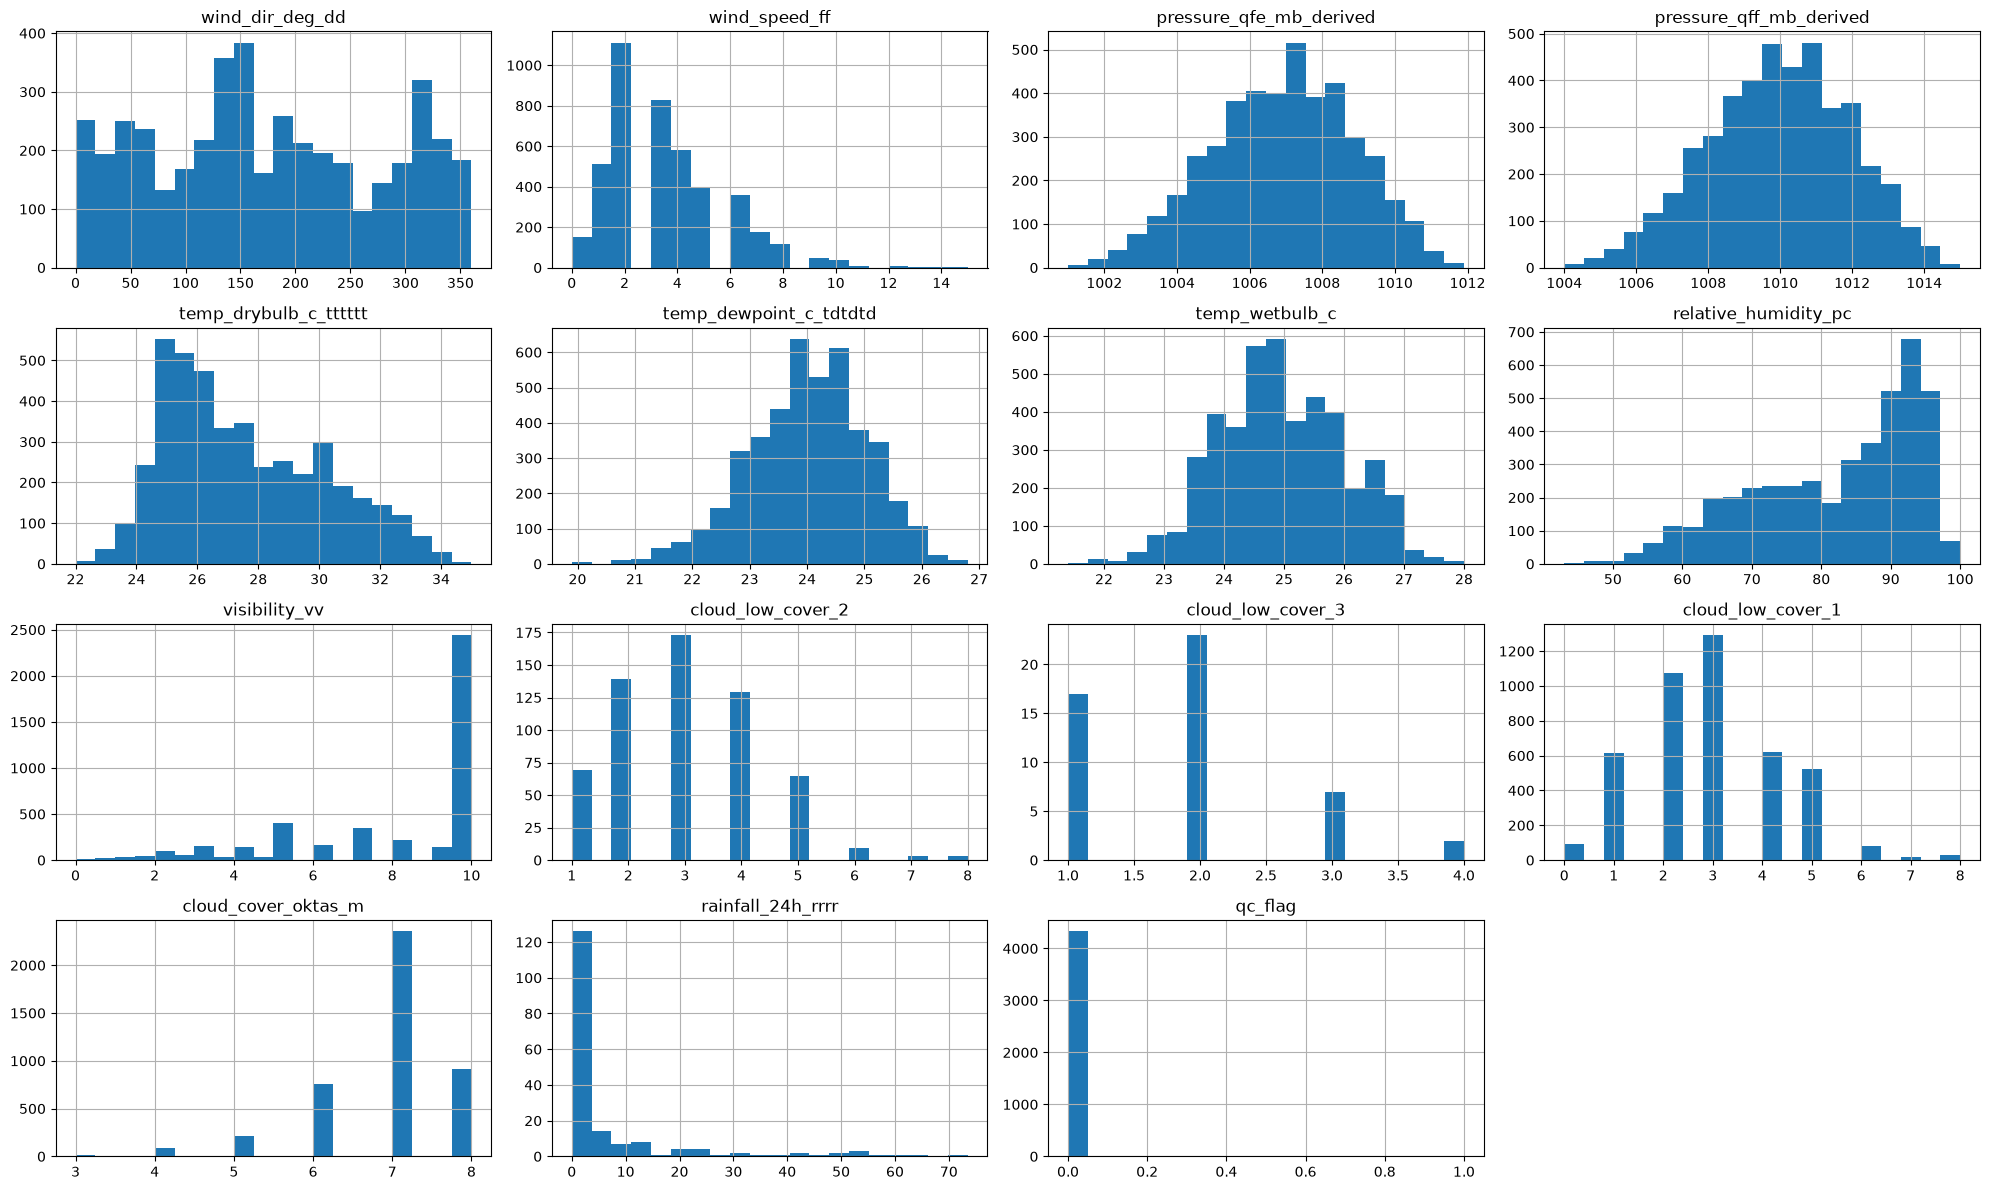

In [288]:
temp_df.hist(figsize=(20,12), bins=20)
plt.tight_layout()
plt.show()

**Notes:**

Sebagian besar variabel numerik menunjukkan distribusi yang cukup wajar tanpa outlier ekstrem, kecuali `rainfall_24h_rrrr` yang awalnya terdistorsi oleh kode sentinel 8888. Variabel `cloud_low_cover_2` dan `cloud_low_cover_3` memiliki jumlah data yang sangat terbatas akibat sifatnya yang hanya tercatat bila lapisan awan tambahan teramati.

## 2.2 Bivariate Analysis (Correlation with Visibility)

Mengukur kekuatan hubungan antara setiap variabel dengan `visibility_vv` menggunakan koefisien korelasi, untuk mengidentifikasi fitur yang berpotensi paling berpengaruh terhadap target.

In [289]:
correlation = temp_df.corr(numeric_only=True)['visibility_vv'].sort_values()
correlation

relative_humidity_pc      -0.589639
cloud_low_cover_2         -0.382694
cloud_low_cover_3         -0.302869
temp_dewpoint_c_tdtdtd    -0.150071
pressure_qff_mb_derived   -0.097540
pressure_qfe_mb_derived   -0.093417
cloud_cover_oktas_m       -0.086889
qc_flag                   -0.045734
rainfall_24h_rrrr         -0.038113
wind_dir_deg_dd            0.023029
cloud_low_cover_1          0.068292
temp_wetbulb_c             0.239960
wind_speed_ff              0.347619
temp_drybulb_c_tttttt      0.520088
visibility_vv              1.000000
Name: visibility_vv, dtype: float64

<Axes: xlabel='relative_humidity_pc', ylabel='visibility_vv'>

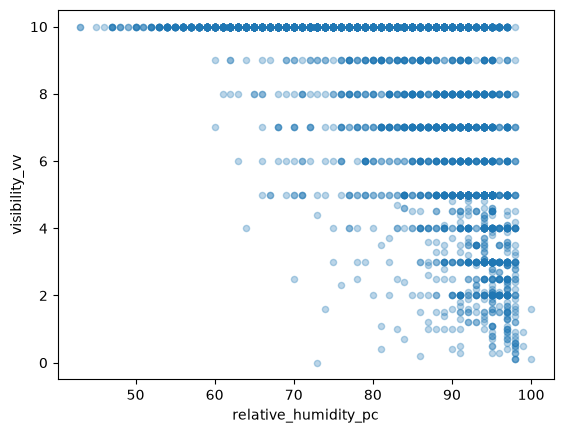

In [290]:
temp_df.plot.scatter(x='relative_humidity_pc', y='visibility_vv', alpha=0.3)

<Axes: xlabel='temp_drybulb_c_tttttt', ylabel='visibility_vv'>

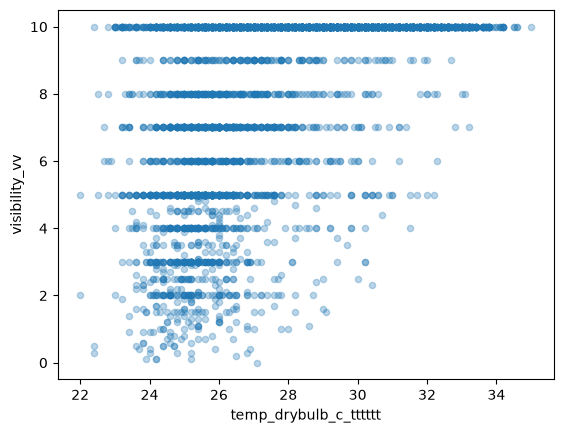

In [291]:
temp_df.plot.scatter(x='temp_drybulb_c_tttttt', y='visibility_vv', alpha=0.3)

**Notes:**

`relative_humidity_pc` (-0.59) dan `temp_drybulb_c_tttttt` (+0.52) menunjukkan korelasi terkuat terhadap `visibility_vv`, sejalan dengan pola pembentukan kabut (kelembapan tinggi dan suhu rendah). `wind_speed_ff` (+0.35) turut berkontribusi, sedangkan variabel `cloud_low_cover_1` menunjukkan korelasi yang mengejutkan lemah (+0.07), mengindikasikan hubungan yang mungkin bersifat non-linear atau memerlukan kombinasi dengan variabel lain untuk terlihat jelas.

## 2.3 Multivariate Analysis (Correlation Heatmap & Feature Interaction)

Melihat hubungan antar seluruh variabel secara bersamaan melalui correlation heatmap, untuk mengidentifikasi potensi multikolinearitas antar fitur serta pola interaksi yang tidak terlihat pada analisis bivariat.

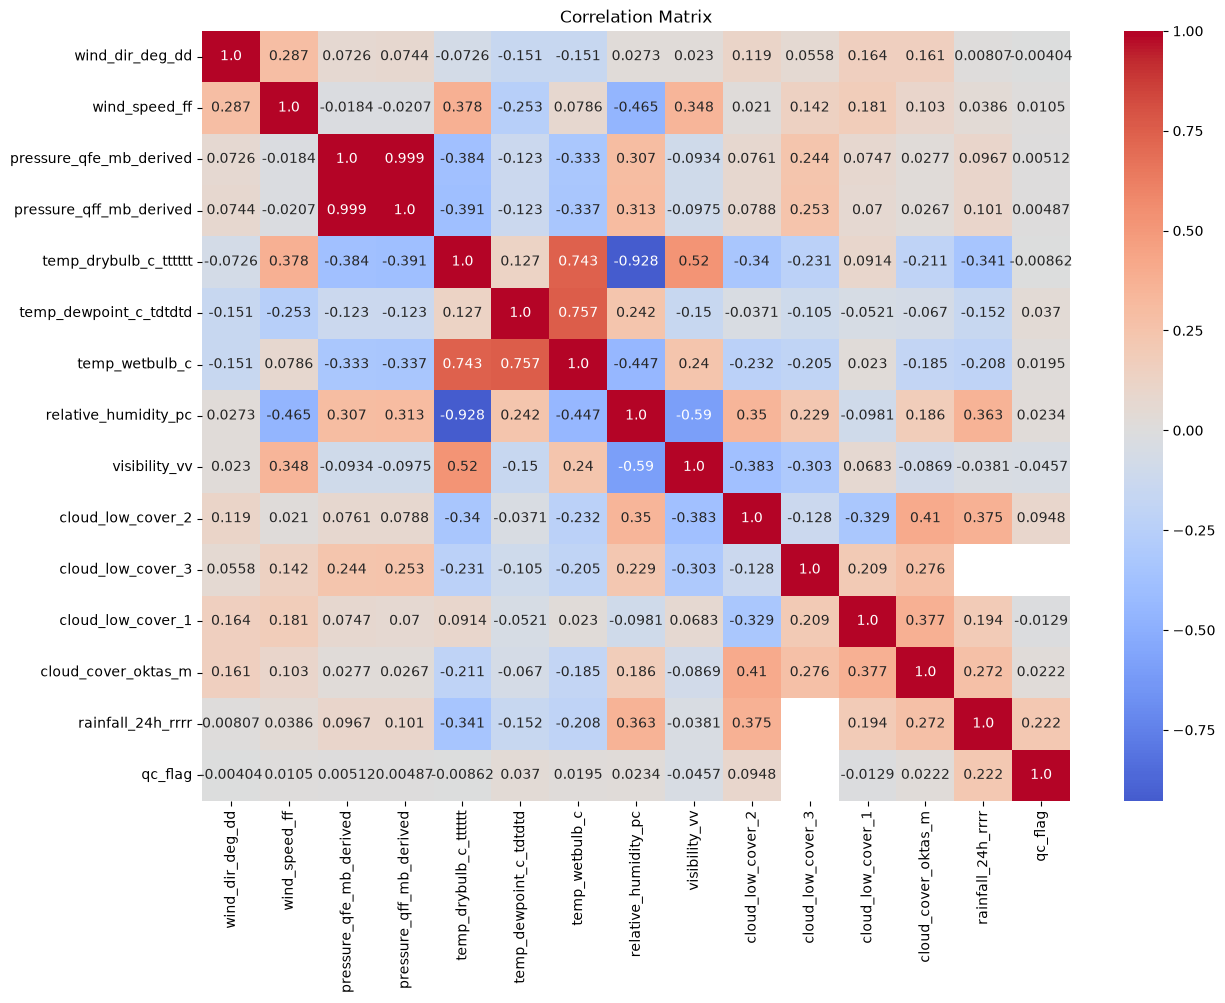

In [292]:
plt.figure(figsize=(14, 10))

sns.heatmap(temp_df.corr(numeric_only=True), annot=True, fmt='0.3', cmap='coolwarm', center=0)
plt.title('Correlation Matrix')

plt.show()

**Notes:**

Ditemukan multikolinearitas sangat tinggi antara pressure_`qfe_mb_derived` dan `pressure_qff_mb_derived` (0.999), serta antara `temp_drybulb_c_tttttt` dan `relative_humidity_pc` (-0.928). Temuan ini mengindikasikan hubungan fisik yang kuat antar variabel suhu dan kelembapan, dan mendukung pembuatan fitur turunan `dewpoint_depression` sebagai representasi tambahan yang merangkum jarak udara terhadap titik jenuhnya. Variabel suhu dan kelembapan mentah tetap dipertahankan sebagai fitur terpisah, mengingat model berbasis pohon keputusan relatif tahan terhadap multikolinearitas dan tetap dapat memanfaatkan informasi dari ketiga variabel tersebut secara independen.

## 2.4 Temporal Pattern Analysis

Menganalisis pola visibility berdasarkan waktu untuk mengindentifikasi pola diurnal maupun musiman yang relevan dengan penomena pembentukan kabut

In [293]:
temp_df.columns

Index(['station_name', 'data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
       'relative_humidity_pc', 'visibility_vv', 'cloud_low_cover_2',
       'cloud_low_cover_3', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
       'rainfall_24h_rrrr', 'created_at', 'updated_at', 'qc_flag',
       'qc_histories', 'observer_name'],
      dtype='str')

In [294]:
temp_df['data_timestamp'] = pd.to_datetime(temp_df['data_timestamp'])

`VISIBILITY`

**HOUR**

In [295]:
temp_df['hour'] = temp_df['data_timestamp'].dt.hour

In [296]:
hourly_vis = temp_df.groupby('hour')['visibility_vv'].agg(['mean', 'median', 'min'])
print(hourly_vis)

          mean  median  min
hour                       
0     4.945304     4.5  0.1
1     7.355249     7.0  0.1
2     9.225414    10.0  2.8
3     9.693370    10.0  1.5
4     9.791713    10.0  1.3
5     9.704420    10.0  2.0
6     9.625967    10.0  1.0
7     9.597790    10.0  0.7
8     9.487845    10.0  0.3
9     9.491713    10.0  0.4
10    9.261878    10.0  1.0
11    9.010497    10.0  0.2
12    8.650829    10.0  2.0
13    8.554696    10.0  1.8
14    8.137017    10.0  0.0
15    7.909945     9.0  1.0
16    7.457459     7.0  1.5
17    7.064088     7.0  1.2
18    6.753591     7.0  0.7
19    6.470166     7.0  0.3
20    6.420994     6.0  0.6
21    6.050276     5.0  0.5
22    5.862431     5.0  0.6
23    4.923204     5.0  0.1


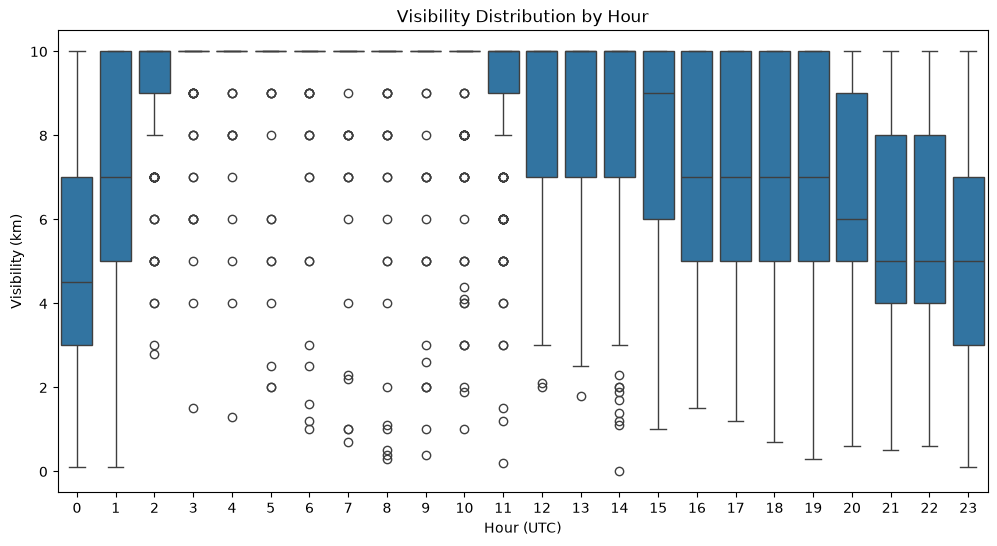

In [297]:
plt.figure(figsize=(12, 6))

sns.boxplot(x='hour', y='visibility_vv', data=temp_df)
plt.title('Visibility Distribution by Hour')
plt.xlabel('Hour (UTC)')
plt.ylabel('Visibility (km)')

plt.show()

**MONTH**

In [298]:
temp_df['month'] = temp_df['data_timestamp'].dt.month

In [299]:
mounthly_vis = temp_df.groupby('month')['visibility_vv'].agg(['mean', 'median', 'min'])
print(mounthly_vis)

           mean  median  min
month                       
1      8.384140    10.0  0.6
2      8.595238    10.0  0.0
3      8.006183    10.0  0.5
4      7.985833    10.0  0.1
5      7.715188    10.0  0.2
6      7.210278     8.0  0.3


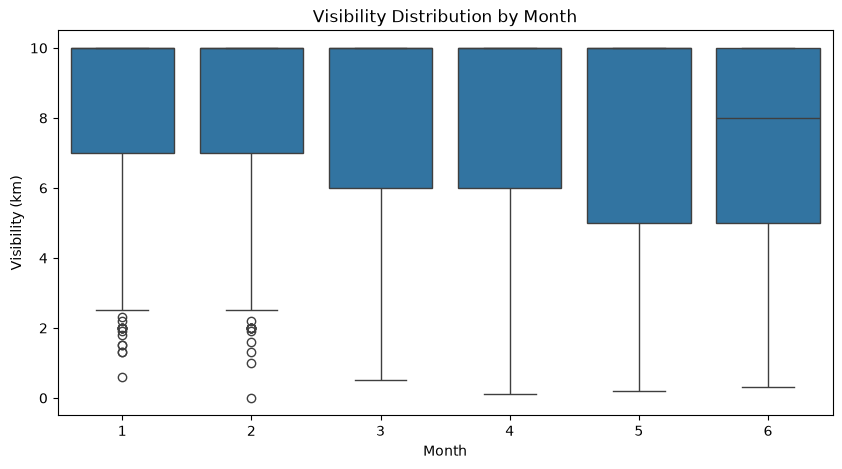

In [300]:
plt.figure(figsize=(10,5))

sns.boxplot(x='month', y='visibility_vv', data=temp_df)
plt.title('Visibility Distribution by Month')
plt.xlabel('Month')
plt.ylabel('Visibility (km)')

plt.show()

`RAINFALL by MONTH`

In [301]:
monthly_rain = temp_df.groupby('month')['rainfall_24h_rrrr'].agg(['mean', 'median'])
print(monthly_rain)

            mean  median
month                   
1       6.508065   0.050
2       3.694643   0.050
3       4.824194   0.600
4       5.906667   1.550
5      14.569355   3.800
6       7.055000   0.125


In [302]:
count_rain = temp_df[temp_df['rainfall_24h_rrrr'] > 0].groupby('month').size()
print(count_rain)

month
1    18
2    15
3    17
4    24
5    23
6    16
dtype: int64


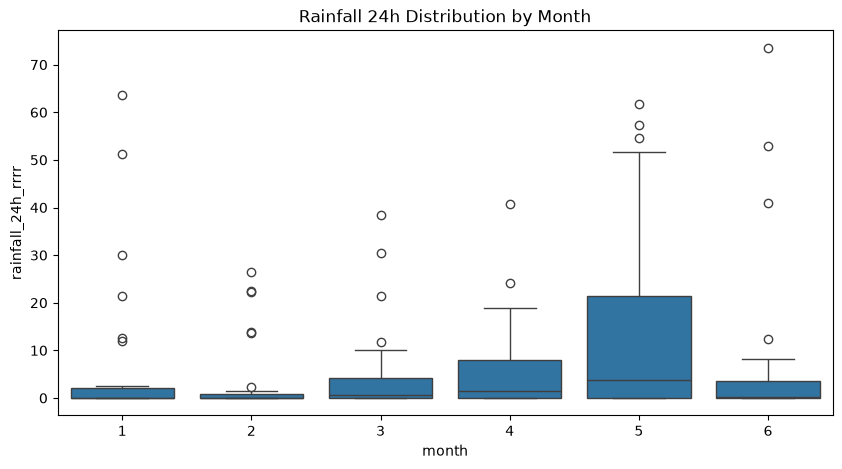

In [303]:
plt.figure(figsize=(10,5))

sns.boxplot(x='month', y='rainfall_24h_rrrr', data=temp_df)
plt.title('Rainfall 24h Distribution by Month')

plt.show()

## 2.5 Target Variable Analysis

Melihat sebaran `visibility_vv` dan proporsi kelas berdasarkan threshold sementara, untuk mengidentifikasi potensi ketidakseimbangan kelas.

In [304]:
temp_df['vis_class'] = np.select(
    [temp_df['visibility_vv'] < 2,
    temp_df['visibility_vv'] < 5],
    ['low', 'medium'],
    default='high'
)

In [305]:
print(temp_df['vis_class'].value_counts())
print(temp_df['vis_class'].value_counts(normalize=True))

vis_class
high      3718
medium     512
low        114
Name: count, dtype: int64
vis_class
high      0.855893
medium    0.117864
low       0.026243
Name: proportion, dtype: float64


## 2.6 Feature Distribution by Visibility Class

Membandingkan sebaran fitur utama pada tiap kelas visibility, untuk melihat fitur mana yang mampu membedakan kelas.

In [306]:
features = ['relative_humidity_pc', 'temp_drybulb_c_tttttt', 'temp_wetbulb_c',
            'wind_speed_ff', 'wind_dir_deg_dd', 'cloud_cover_oktas_m',
            'cloud_low_cover_1', 'cloud_low_cover_2', 'cloud_low_cover_3',
            'temp_dewpoint_c_tdtdtd', 'pressure_qff_mb_derived', 'pressure_qfe_mb_derived',
            'rainfall_24h_rrrr'
]

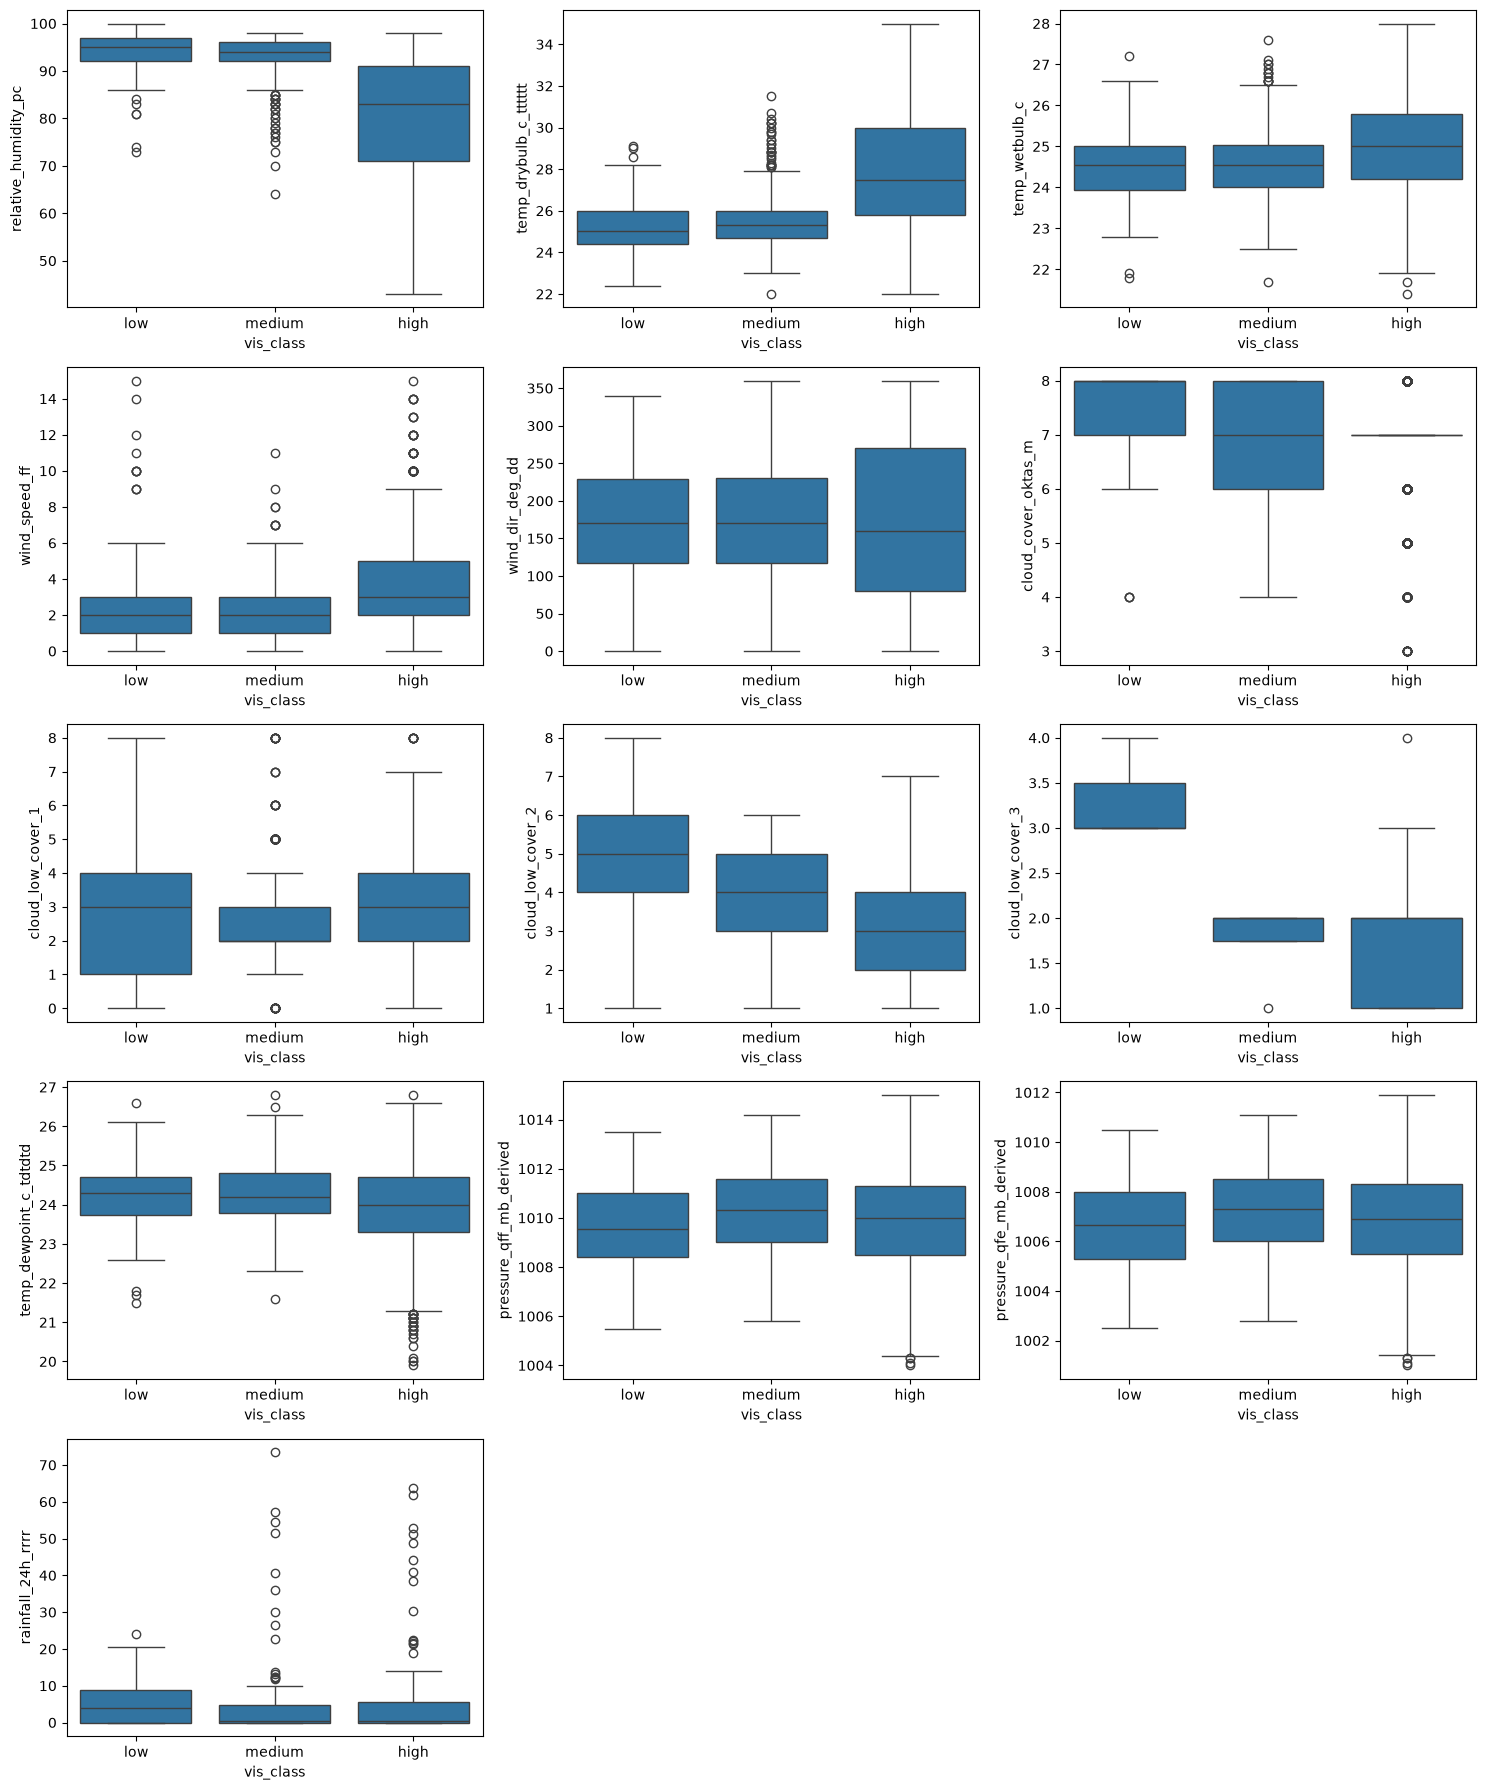

In [307]:
fig, axes = plt.subplots(5, 3, figsize=(15,18))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.boxplot(x='vis_class', y=col, data=temp_df, order=['low', 'medium', 'high'], ax=ax)

for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 2.7 Low Visibility Episode Analysis

Menganalisis kapan kejadian visibility rendah muncul dan berapa lama durasinya, untuk memahami karakteristik episode kabut.

In [308]:
low = temp_df[temp_df['vis_class'] == 'low']

print('HOURLY LOW VISIBILITY')
print(low['data_timestamp'].dt.hour.value_counts().sort_index())

print('\nMONTHLY LOW VISIBILITY')
print(low['data_timestamp'].dt.month.value_counts().sort_index())

HOURLY LOW VISIBILITY
data_timestamp
0     14
1      2
3      1
4      1
6      3
7      3
8      5
9      2
10     2
11     3
13     1
14     6
15     1
16     2
17     8
18     5
19     8
20     7
21    11
22     8
23    21
Name: count, dtype: int64

MONTHLY LOW VISIBILITY
data_timestamp
1     7
2     5
3    17
4    34
5    29
6    22
Name: count, dtype: int64


In [309]:
is_low = temp_df['vis_class'] == 'low'
run_id = (is_low != is_low.shift()).cumsum()
runs = is_low.groupby(run_id).agg(['first', 'size'])
print(runs[runs['first']]['size'].describe())

count    71.000000
mean      1.605634
std       1.176907
min       1.000000
25%       1.000000
50%       1.000000
75%       2.000000
max       7.000000
Name: size, dtype: float64


# 3. Preprocessing

Tahap ini melakukan pembersihan dan transformasi data berdasarkan seluruh temuan dari tahap Inspection dan EDA sebelumnya, agar data siap digunakan untuk pemodelan. Seluruh proses dilakukan pada salinan data (clean_df), sehingga data_df asli tetap terjaga sebagai referensi mentah.

## 3.1 Create Working Copy

Membuat salinan dataframe untuk diproses, agar data mentah asli (data_df) tetap tersimpan sebagai referensi.

In [310]:
clean_df = data_df.copy()
clean_df.head()

,station_name,data_timestamp,wind_dir_deg_dd,wind_speed_ff,pressure_qfe_mb_derived,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,...,cloud_low_cover_2,cloud_low_cover_3,cloud_low_cover_1,cloud_cover_oktas_m,rainfall_24h_rrrr,created_at,updated_at,qc_flag,qc_histories,observer_name
0,Stasiun Meteorologi Sultan Thaha,2026-01-01 00:00:00,130,2,1006.0,1009.1,23.6,23.2,23.3,98,...,NaN,NaN,4,8,12.0,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Mustar Puad
1,Stasiun Meteorologi Sultan Thaha,2026-01-01 01:00:00,120,4,1007.2,1010.1,24.0,23.3,23.5,96,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
2,Stasiun Meteorologi Sultan Thaha,2026-01-01 02:00:00,310,5,1007.6,1010.6,25.0,23.2,23.7,90,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
3,Stasiun Meteorologi Sultan Thaha,2026-01-01 03:00:00,300,5,1007.9,1010.9,26.0,23.5,24.2,86,...,NaN,NaN,4,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus
4,Stasiun Meteorologi Sultan Thaha,2026-01-01 04:00:00,260,5,1007.4,1010.4,27.2,23.3,24.4,79,...,NaN,NaN,2,8,NaN,2026-02-04 15:49:25,2026-02-04 15:49:25,0,NaN,Eko Berlin Sitorus


## 3.2 Fix Data Structure

Mengonversi tipe data yang belum sesuai (datetime, numerik) sesuai temuan pada tahap Inspection, seperti kolom `data_timestamp` dan `cloud_low_cover_1`

In [311]:
clean_df['data_timestamp'] = pd.to_datetime(clean_df['data_timestamp'], errors='coerce')
clean_df['cloud_low_cover_1'] = pd.to_numeric(clean_df['cloud_low_cover_1'], errors='coerce')

print(clean_df[['data_timestamp', 'cloud_low_cover_1']].dtypes)

data_timestamp       datetime64[us]
cloud_low_cover_1           float64
dtype: object


## 3.3 Drop Unused Columns

Membuang kolom yang tidak akan digunakan dalam pemodelan, untuk menyederhanakan dataset.

In [312]:
clean_df.columns

Index(['station_name', 'data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qfe_mb_derived', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c',
       'relative_humidity_pc', 'visibility_vv', 'cloud_low_cover_2',
       'cloud_low_cover_3', 'cloud_low_cover_1', 'cloud_cover_oktas_m',
       'rainfall_24h_rrrr', 'created_at', 'updated_at', 'qc_flag',
       'qc_histories', 'observer_name'],
      dtype='str')

In [313]:
clean_df.drop(columns=(['station_name', 'pressure_qfe_mb_derived', 'created_at', 'updated_at', 'qc_histories', 'observer_name']), inplace=True)
clean_df.columns

Index(['data_timestamp', 'wind_dir_deg_dd', 'wind_speed_ff',
       'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt',
       'temp_dewpoint_c_tdtdtd', 'temp_wetbulb_c', 'relative_humidity_pc',
       'visibility_vv', 'cloud_low_cover_2', 'cloud_low_cover_3',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'rainfall_24h_rrrr',
       'qc_flag'],
      dtype='str')

## 3.4 Handle Missing Values

Menangani nilai hilang pada variabel yang teridentifikasi memiliki missing value, seperti `cloud_low_cover_1`, `cloud_low_cover_2`, `cloud_low_cover_3`, dan `rainfall_24h_rrrr`

### `cloud_low_cover_1`

In [314]:
clean_df[clean_df['cloud_low_cover_1'].isna()][['cloud_low_cover_1', 'cloud_low_cover_2', 'cloud_low_cover_3', 'cloud_cover_oktas_m', 'visibility_vv']]

,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_cover_oktas_m,visibility_vv
357,NaN,NaN,NaN,8,6.0
2076,NaN,NaN,NaN,7,5.0
2783,NaN,NaN,NaN,6,1.4


In [315]:
idx_nan = clean_df[clean_df['cloud_low_cover_1'].isna()].index
idx_before = idx_nan - 1
idx_after = idx_nan + 1
idx_all = idx_nan.union(idx_before).union(idx_after).sort_values()

clean_df.loc[idx_all, ['cloud_low_cover_1', 'cloud_low_cover_2', 'cloud_low_cover_3', 'cloud_cover_oktas_m', 'visibility_vv']]

,cloud_low_cover_1,cloud_low_cover_2,cloud_low_cover_3,cloud_cover_oktas_m,visibility_vv
356,3.0,NaN,NaN,8,6.0
357,NaN,NaN,NaN,8,6.0
358,4.0,NaN,NaN,8,5.0
2075,1.0,NaN,NaN,8,7.0
2076,NaN,NaN,NaN,7,5.0
2077,3.0,NaN,NaN,8,5.0
2782,2.0,NaN,NaN,6,1.8
2783,NaN,NaN,NaN,6,1.4
2784,0.0,NaN,NaN,5,8.0


In [316]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].ffill()
print(clean_df['cloud_low_cover_1'].isna().sum())

0


### `cloud_low_cover_2`

In [317]:
position = clean_df.columns.get_loc('cloud_low_cover_2') + 1
clean_df.insert(position, 'has_cloud_layer_2', clean_df['cloud_low_cover_2'].notna().astype('int8'))
clean_df['cloud_low_cover_2'] = clean_df['cloud_low_cover_2'].fillna(0)

In [318]:
print('cloud_low_cover_2 missing: ', clean_df['cloud_low_cover_2'].isna().sum())
print('has_cloud_layer_2 missing: ', clean_df['has_cloud_layer_2'].isna().sum())

cloud_low_cover_2 missing:  0
has_cloud_layer_2 missing:  0


In [319]:
clean_df.loc[clean_df['cloud_low_cover_2'] == 0, ['cloud_low_cover_2', 'has_cloud_layer_2']].head(5)

,cloud_low_cover_2,has_cloud_layer_2
0,0.0,0
1,0.0,0
2,0.0,0
3,0.0,0
4,0.0,0


In [320]:
clean_df.loc[clean_df['cloud_low_cover_2'] != 0, ['cloud_low_cover_2', 'has_cloud_layer_2']].head(5)

,cloud_low_cover_2,has_cloud_layer_2
19,4.0,1
20,4.0,1
21,4.0,1
23,4.0,1
24,4.0,1


### `cloud_low_cover_3`

In [321]:
position = clean_df.columns.get_loc('cloud_low_cover_3') + 1
clean_df.insert(position, 'has_cloud_layer_3', clean_df['cloud_low_cover_3'].notna().astype('int8'))
clean_df['cloud_low_cover_3'] = clean_df['cloud_low_cover_3'].fillna(0)

In [322]:
print('cloud_low_cover_3 missing: ', clean_df['cloud_low_cover_3'].isna().sum())
print('has_cloud_layer_3 missing: ', clean_df['has_cloud_layer_3'].isna().sum())

cloud_low_cover_3 missing:  0
has_cloud_layer_3 missing:  0


In [323]:
clean_df.loc[clean_df['cloud_low_cover_3'] == 0, ['cloud_low_cover_3', 'has_cloud_layer_3']].head(5)

,cloud_low_cover_3,has_cloud_layer_3
0,0.0,0
1,0.0,0
2,0.0,0
3,0.0,0
4,0.0,0


In [324]:
clean_df.loc[clean_df['cloud_low_cover_3'] != 0, ['cloud_low_cover_3', 'has_cloud_layer_3']].head(5)

,cloud_low_cover_3,has_cloud_layer_3
155,1.0,1
394,1.0,1
1473,2.0,1
1474,2.0,1
1475,2.0,1


### `rainfall_24h_rrrr`

**Mengganti sentinel 8888 menjadi nilai mendekati 0**

In [325]:
clean_df['rainfall_24h_rrrr'] = clean_df['rainfall_24h_rrrr'].replace(8888, 0.05)

**Catatan:** 

0.05 (bukan 0 murni) dipakai karena 8888 itu artinya ada hujan tapi sangat sedikit, bukan benar-benar tidak hujan.

**Menyebarkan nilai harian ke semua jam di hari yang sama**

In [326]:
clean_df.loc[clean_df['rainfall_24h_rrrr'].notna(), ['data_timestamp', 'rainfall_24h_rrrr']].head(5)

,data_timestamp,rainfall_24h_rrrr
0,2026-01-01,12.0
24,2026-01-02,21.4
48,2026-01-03,51.3
72,2026-01-04,0.5
96,2026-01-05,0.0


In [327]:
clean_df['rainfall_24h_rrrr'].value_counts().sort_index().head(5)

rainfall_24h_rrrr
0.00    68
0.05    17
0.20     3
0.40     2
0.50     2
Name: count, dtype: int64

In [328]:
clean_df['date'] = pd.to_datetime(clean_df['data_timestamp'] - pd.Timedelta(hours=1)).dt.date
clean_df['rainfall_24h_rrrr'] = clean_df.groupby('date')['rainfall_24h_rrrr'].transform(lambda x: x.ffill().bfill())
clean_df.drop(columns=['date'], inplace=True)

In [329]:
print('rainfall_24h_rrrr missing: ', clean_df['rainfall_24h_rrrr'].isna().sum())
print('rainfall_24h_rrrr max value: ', clean_df['rainfall_24h_rrrr'].max())

rainfall_24h_rrrr missing:  23
rainfall_24h_rrrr max value:  73.5


In [330]:
clean_df[['data_timestamp', 'rainfall_24h_rrrr']].tail(5)

,data_timestamp,rainfall_24h_rrrr
4339,2026-06-30 19:00:00,NaN
4340,2026-06-30 20:00:00,NaN
4341,2026-06-30 21:00:00,NaN
4342,2026-06-30 22:00:00,NaN
4343,2026-06-30 23:00:00,NaN


**Drop 23 baris terakhir karena rainfall tidak terlaporkan**

In [331]:
clean_df = clean_df.dropna(subset=['rainfall_24h_rrrr'])

In [332]:
print('rainfall_24h_rrrr missing: ', clean_df['rainfall_24h_rrrr'].isna().sum())
print('clean_df shape: ', clean_df.shape)
print('maximum datetime of dataset: ', clean_df['data_timestamp'].max())

rainfall_24h_rrrr missing:  0
clean_df shape:  (4321, 17)
maximum datetime of dataset:  2026-06-30 00:00:00


## 3.5 Finalize Data Types

Mengonversi kembali kolom yang sempat bertipe float akibat adanya missing value menjadi integer, setelah seluruh nilai hilang berhasil ditangani pada tahap sebelumnya.

In [333]:
clean_df['cloud_low_cover_1'] = clean_df['cloud_low_cover_1'].astype('int8')
clean_df['cloud_low_cover_2'] = clean_df['cloud_low_cover_2'].astype('int8')
clean_df['cloud_low_cover_3'] = clean_df['cloud_low_cover_3'].astype('int8')
clean_df['cloud_cover_oktas_m'] = clean_df['cloud_cover_oktas_m'].astype('int8')

In [334]:
clean_df[['cloud_low_cover_1', 'cloud_low_cover_2', 'has_cloud_layer_2', 'cloud_low_cover_3', 'has_cloud_layer_3', 'cloud_cover_oktas_m']].dtypes

cloud_low_cover_1      int8
cloud_low_cover_2      int8
has_cloud_layer_2      int8
cloud_low_cover_3      int8
has_cloud_layer_3      int8
cloud_cover_oktas_m    int8
dtype: object

In [335]:
clean_df[['cloud_low_cover_1', 'cloud_low_cover_2', 'has_cloud_layer_2', 'cloud_low_cover_3', 'has_cloud_layer_3', 'cloud_cover_oktas_m']].head(5)

,cloud_low_cover_1,cloud_low_cover_2,has_cloud_layer_2,cloud_low_cover_3,has_cloud_layer_3,cloud_cover_oktas_m
0,4,0,0,0,0,8
1,4,0,0,0,0,8
2,4,0,0,0,0,8
3,4,0,0,0,0,8
4,2,0,0,0,0,8


## 3.6 Convert Timestamp to Local Time (WIB)

Mengonversi `data_timestamp` dari UTC ke WIB (UTC+7), agar analisis dan fitur berbasis waktu selanjutnya konsisten dengan pola diurnal visibility yang telah diidentifikasi pada tahap EDA.

In [336]:
date_position = clean_df.columns.get_loc('data_timestamp') + 1
clean_df.insert(date_position, 'datetime_wib', clean_df['data_timestamp'] + pd.Timedelta(hours=7))

In [337]:
clean_df[['data_timestamp', 'datetime_wib']].head(5)

,data_timestamp,datetime_wib
0,2026-01-01 00:00:00,2026-01-01 07:00:00
1,2026-01-01 01:00:00,2026-01-01 08:00:00
2,2026-01-01 02:00:00,2026-01-01 09:00:00
3,2026-01-01 03:00:00,2026-01-01 10:00:00
4,2026-01-01 04:00:00,2026-01-01 11:00:00


In [338]:
print('first date: ', clean_df['datetime_wib'].min())
print('last date: ', clean_df['datetime_wib'].max())

first date:  2026-01-01 07:00:00
last date:  2026-06-30 07:00:00


In [339]:
clean_df.head(5)

,data_timestamp,datetime_wib,wind_dir_deg_dd,wind_speed_ff,pressure_qff_mb_derived,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,temp_wetbulb_c,relative_humidity_pc,visibility_vv,cloud_low_cover_2,has_cloud_layer_2,cloud_low_cover_3,has_cloud_layer_3,cloud_low_cover_1,cloud_cover_oktas_m,rainfall_24h_rrrr,qc_flag
0,2026-01-01 00:00:00,2026-01-01 07:00:00,130,2,1009.1,23.6,23.2,23.3,98,3.0,0,0,0,0,4,8,12.0,0
1,2026-01-01 01:00:00,2026-01-01 08:00:00,120,4,1010.1,24.0,23.3,23.5,96,5.0,0,0,0,0,4,8,21.4,0
2,2026-01-01 02:00:00,2026-01-01 09:00:00,310,5,1010.6,25.0,23.2,23.7,90,10.0,0,0,0,0,4,8,21.4,0
3,2026-01-01 03:00:00,2026-01-01 10:00:00,300,5,1010.9,26.0,23.5,24.2,86,10.0,0,0,0,0,4,8,21.4,0
4,2026-01-01 04:00:00,2026-01-01 11:00:00,260,5,1010.4,27.2,23.3,24.4,79,10.0,0,0,0,0,2,8,21.4,0


# 4. Feature Engineering

Tahap ini membuat variabel-variabel baru dari data yang telah dibersihkan, berdasarkan insight yang ditemukan pada tahap EDA, untuk meningkatkan kemampuan model dalam menangkap pola yang relevan terhadap visibility.

## 4.1 Dewpoint Depression

Menghitung selisih antara suhu udara dan titik embun `(temp_drybulb_c_tttttt - temp_dewpoint_c_tdtdtd)`, untuk merangkum informasi suhu dan kelembapan secara lebih ringkas dan mengurangi redundansi akibat multikolinearitas tinggi antar keduanya.

**Dew point depression**, yaitu <u>*selisih antara suhu udara dan titik embun*</u>, merupakan indikator penting dalam mengidentifikasi potensi pembentukan kabut. Semakin kecil nilai selisih ini, semakin dekat kondisi udara terhadap titik saturasi, yang meningkatkan kemungkinan terbentuknya kabut atau penurunan visibility.

**Dew point** (titik embun) itu suhu di mana udara harus didinginkan sampai jadi **jenuh/saturated** (kelembapan relatif = 100%), sampai uap air mulai mengembun jadi titik-titik air (contoh: embun di rumput pagi hari, atau kabut).

Jadi **dew point depression** itu ngukur **seberapa "jauh" suhu udara saat ini dari titik jenuhnya**:
- **Depression kecil** (temp dan dew point deket) → udara hampir jenuh, kelembapan tinggi, kondisi mendekati pembentukan kabut/embun
- **Depression besar** (temp dan dew point jauh) → udara masih jauh dari jenuh, kelembapan relatif rendah, kecil kemungkinan kabut

```
Temp = 25°C, Dew Point = 24°C  →  Depression = 1°C   (udara SANGAT lembap, dekat titik jenuh)
Temp = 30°C, Dew Point = 15°C  →  Depression = 15°C  (udara kering, jauh dari jenuh)
```

In [340]:
dew_dep_position = clean_df.columns.get_loc('temp_dewpoint_c_tdtdtd') + 1
clean_df.insert(dew_dep_position, 'dewpoint_depression', clean_df['temp_drybulb_c_tttttt'] - clean_df['temp_dewpoint_c_tdtdtd'])

In [341]:
clean_df[['temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd', 'dewpoint_depression']].head(5)

,temp_drybulb_c_tttttt,temp_dewpoint_c_tdtdtd,dewpoint_depression
0,23.6,23.2,0.4
1,24.0,23.3,0.7
2,25.0,23.2,1.8
3,26.0,23.5,2.5
4,27.2,23.3,3.9


In [342]:
clean_df['dewpoint_depression'].describe()

count    4321.000000
mean        3.538556
std         2.674562
min         0.000000
25%         1.400000
50%         2.700000
75%         5.400000
max        14.600000
Name: dewpoint_depression, dtype: float64

## 4.2 Wind Direction Encoding (Sin/Cos)

Mengonversi `wind_dir_deg_dd` menjadi representasi sin dan cos, karena arah angin bersifat sirkular (0° dan 360° merepresentasikan arah yang sama) sehingga tidak bisa diperlakukan sebagai nilai linear biasa.

In [343]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 1
clean_df.insert(position, 'wind_dir_sin', np.sin(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [344]:
position = clean_df.columns.get_loc('wind_dir_deg_dd') + 2
clean_df.insert(position, 'wind_dir_cos', np.cos(np.deg2rad(clean_df['wind_dir_deg_dd'])))

In [345]:
wind_direction = clean_df[['wind_dir_deg_dd', 'wind_dir_sin', 'wind_dir_cos']]

In [346]:
wind_direction.isna().sum()

wind_dir_deg_dd    0
wind_dir_sin       0
wind_dir_cos       0
dtype: int64

In [347]:
wind_direction.head(5)

,wind_dir_deg_dd,wind_dir_sin,wind_dir_cos
0,130,0.766044,-0.642788
1,120,0.866025,-0.500000
2,310,-0.766044,0.642788
3,300,-0.866025,0.500000
4,260,-0.984808,-0.173648


## 4.3 Cyclical Time Encoding

Mengonversi jam dan bulan menjadi representasi sin dan cos, agar model dapat menangkap sifat siklis waktu (misalnya jam 23:00 dekat dengan jam 00:00).

**Ekstraksi Fitur Waktu Dasar**

In [348]:
position = clean_df.columns.get_loc('datetime_wib') + 1
clean_df.insert(position, 'hour', clean_df['datetime_wib'].dt.hour)

In [349]:
position = clean_df.columns.get_loc('datetime_wib') + 2
clean_df.insert(position, 'month', clean_df['datetime_wib'].dt.month)

**Cyclic Encoding for Hour (Periode 24 Jam)**

In [350]:
position = clean_df.columns.get_loc('hour') + 1
clean_df.insert(position, 'hour_sin', np.sin(2 * np.pi * clean_df['hour'] / 24))
position = clean_df.columns.get_loc('hour') + 2
clean_df.insert(position, 'hour_cos', np.cos(2 * np.pi * clean_df['hour'] / 24))

In [351]:
position = clean_df.columns.get_loc('month') + 1
clean_df.insert(position, 'month_sin', np.sin(2 * np.pi * clean_df['month'] / 12))
position = clean_df.columns.get_loc('month') + 2
clean_df.insert(position, 'month_cos', np.cos(2 * np.pi * clean_df['month'] / 12))

In [352]:
time = clean_df[['datetime_wib', 'hour', 'hour_sin', 'hour_cos', 'month', 'month_sin', 'month_cos']]

In [353]:
time.isna().sum()

datetime_wib    0
hour            0
hour_sin        0
hour_cos        0
month           0
month_sin       0
month_cos       0
dtype: int64

In [354]:
time.head(5)

,datetime_wib,hour,hour_sin,hour_cos,month,month_sin,month_cos
0,2026-01-01 07:00:00,7,0.965926,-0.258819,1,0.5,0.866025
1,2026-01-01 08:00:00,8,0.866025,-0.500000,1,0.5,0.866025
2,2026-01-01 09:00:00,9,0.707107,-0.707107,1,0.5,0.866025
3,2026-01-01 10:00:00,10,0.500000,-0.866025,1,0.5,0.866025
4,2026-01-01 11:00:00,11,0.258819,-0.965926,1,0.5,0.866025


## 4.4 Fog-Prone Hour Indicator

Membuat fitur indikator biner untuk jam-jam rawan kabut (04:00–07:00 WIB), berdasarkan pola diurnal visibility rendah yang ditemukan pada tahap EDA.

In [355]:
fog_prone_hour = temp_df[temp_df['vis_class'] == 'low']['hour'].add(7).mod(24).value_counts().sort_index()
print('Jam-jam rawan kabut: ', fog_prone_hour)

Jam-jam rawan kabut:  hour
0      8
1      5
2      8
3      7
4     11
5      8
6     21
7     14
8      2
10     1
11     1
13     3
14     3
15     5
16     2
17     2
18     3
20     1
21     6
22     1
23     2
Name: count, dtype: int64


In [356]:
position = clean_df.columns.get_loc('visibility_vv') + 1
clean_df.insert(position, 'is_fog_prone_hour', clean_df['hour'].between(4, 7).astype('int8'))

In [357]:
print('Missing: ', clean_df['is_fog_prone_hour'].isna().sum())
clean_df[['visibility_vv', 'is_fog_prone_hour']].head(5)

Missing:  0


,visibility_vv,is_fog_prone_hour
0,3.0,1
1,5.0,0
2,10.0,0
3,10.0,0
4,10.0,0


## 4.5 Lag Features

Membuat fitur `visibility_lag1`, `visibility_lag2`, dan `visibility_lag3` dari nilai visibility pada 1-3 jam sebelumnya, untuk menangkap ketergantungan temporal pada data. Tiga baris pertama yang tidak memiliki data histori dihapus dari dataset.

**Create Lag Features**

In [358]:
position = clean_df.columns.get_loc('visibility_vv') + 2
clean_df.insert(position, 'visibility_lag1', clean_df['visibility_vv'].shift(1))

In [359]:
position = clean_df.columns.get_loc('visibility_vv') + 3
clean_df.insert(position, 'visibility_lag2', clean_df['visibility_vv'].shift(2))

In [360]:
position = clean_df.columns.get_loc('visibility_vv') + 4
clean_df.insert(position, 'visibility_lag3', clean_df['visibility_vv'].shift(3))

In [361]:
visibility_lag = clean_df[['visibility_vv', 'visibility_lag1', 'visibility_lag2', 'visibility_lag3']]

In [362]:
visibility_lag.isna().sum()

visibility_vv      0
visibility_lag1    1
visibility_lag2    2
visibility_lag3    3
dtype: int64

In [363]:
visibility_lag.head(5)

,visibility_vv,visibility_lag1,visibility_lag2,visibility_lag3
0,3.0,NaN,NaN,NaN
1,5.0,3.0,NaN,NaN
2,10.0,5.0,3.0,NaN
3,10.0,10.0,5.0,3.0
4,10.0,10.0,10.0,5.0


**Drop Invalid Lag Features Rows**

In [364]:
before = len(clean_df)
clean_df = clean_df.dropna(subset=['visibility_lag1', 'visibility_lag2', 'visibility_lag3']).reset_index(drop=True)
after = len(clean_df)

In [365]:
print('Baris sebelum didrop: ', before)
print('Baris setelah didrop: ', after)
print('Baris yang didrop: ', round((before-after)/before*100, 2), '%')

Baris sebelum didrop:  4321
Baris setelah didrop:  4318
Baris yang didrop:  0.07 %


# 5. Label Definition

Menentukan kategori label visibility (low, medium, high) berdasarkan ambang batas operasional yang telah divalidasi sebelumnya, untuk mengubah `visibility_vv` dari variabel numerik menjadi target klasifikasi.

## 5.1 Check Visibility Unit

Satuan `visibility_vv` pada dataset BMKG dikonfirmasi dalam kilometer, berdasarkan rentang nilai 0–10 yang telah diperiksa pada tahap Inspection dan kesesuaiannya dengan ambang operasional BMKG (2 km). Satuan ini menjadi dasar penyesuaian threshold pada tahap Label Definition.

## 5.2 Apply Visibility Threshold

Mengelompokkan visibility_vv ke dalam kategori low, medium, dan high berdasarkan ambang batas operasional.
- low < 2km
- medium < 5km
- high >= 5km

In [406]:
def visibility_threshold(visibility):
    if visibility < 2:
        return 'low'
    elif visibility < 5:
        return 'medium'
    else:
        return 'high'

In [407]:
clean_df['visibility_class'] = clean_df['visibility_vv'].apply(visibility_threshold)

## 5.3 Check Class Distribution

Melihat proporsi masing-masing kelas hasil pelabelan, untuk mengidentifikasi tingkat ketidakseimbangan kelas (class imbalance) sebelum masuk ke tahap pemodelan.

In [408]:
clean_df['visibility_class'].value_counts()

visibility_class
high      3699
medium     507
low        112
Name: count, dtype: int64

In [409]:
(clean_df['visibility_class'].value_counts(normalize=True)*100).round(2)

visibility_class
high      85.66
medium    11.74
low        2.59
Name: proportion, dtype: float64

## 5.4 Visualize Class Distribution

Visualisasi distribusi kelas dilakukan untuk melihat secara langsung tingkat ketimpangan (class imbalance) antar kategori, sebagai dasar penentuan strategi penanganan pada tahap pemodelan.

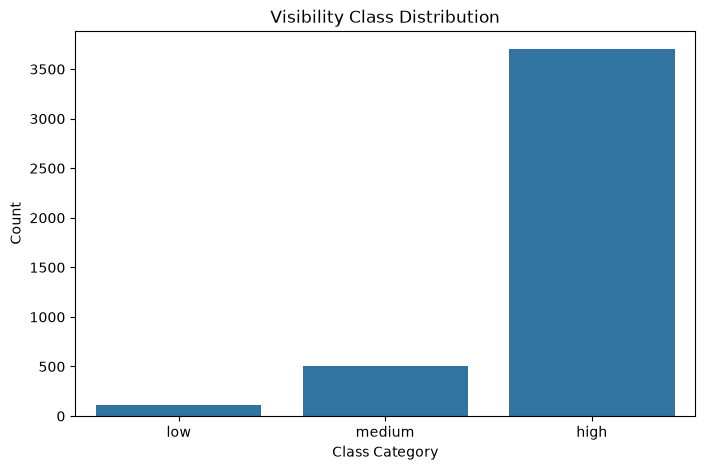

In [410]:
plt.figure(figsize=(8,5))

sns.countplot(x='visibility_class', data=clean_df, order=['low', 'medium', 'high'])
plt.title('Visibility Class Distribution')
plt.xlabel('Class Category')
plt.ylabel('Count')

plt.show()

# 6. Data Splitting

Membagi dataset menjadi data latih (train) dan data uji (test) menggunakan pendekatan time-based split, untuk menjaga urutan kronologis data time-series dan mencegah data leakage dari periode mendatang ke proses pelatihan model.

## 6.1 Time-Based Train-Test Split

Membagi data secara kronologis (bukan random split), dengan data pada periode awal digunakan sebagai train dan periode akhir sebagai test, sesuai karakteristik data time-series

Mengurutkan berdasarkan waktu

In [411]:
clean_df = clean_df.sort_values('datetime_wib').reset_index(drop=True)

Split 80% data awal untuk training dan 20% data akhir untuk testing

In [412]:
split_index = int(len(clean_df)*0.8)

train_df = clean_df[:split_index]
test_df = clean_df[split_index:]

In [413]:
print('Total data: ', len(clean_df), '(', clean_df['datetime_wib'].min(), '-', clean_df['datetime_wib'].max(), ')')
print('Total train: ', len(train_df), '(', train_df['datetime_wib'].min(), '-', train_df['datetime_wib'].max(), ')')
print('Total test: ', len(test_df), '(', test_df['datetime_wib'].min(), '-', test_df['datetime_wib'].max(), ')')

Total data:  4318 ( 2026-01-01 10:00:00 - 2026-06-30 07:00:00 )
Total train:  3454 ( 2026-01-01 10:00:00 - 2026-05-25 07:00:00 )
Total test:  864 ( 2026-05-25 08:00:00 - 2026-06-30 07:00:00 )


In [414]:
time_diff = clean_df['datetime_wib'].diff().value_counts()
time_diff

datetime_wib
0 days 01:00:00    4317
Name: count, dtype: int64

## 6.2 Check Class Distribution in Train vs Test

Memeriksa proporsi kelas visibility pada data train dan test, untuk memastikan representasi tiap kelas (khususnya kelas low yang minoritas) tetap memadai pada kedua kedua subset

**Distribusi Kelas - Train Set**

In [415]:
train_df['visibility_class'].value_counts()

visibility_class
high      3027
medium     347
low         80
Name: count, dtype: int64

In [416]:
(train_df['visibility_class'].value_counts(normalize=True)*100).round(2)

visibility_class
high      87.64
medium    10.05
low        2.32
Name: proportion, dtype: float64

**Distribusi Kelas - Test Set**

In [417]:
test_df['visibility_class'].value_counts()

visibility_class
high      672
medium    160
low        32
Name: count, dtype: int64

In [418]:
(test_df['visibility_class'].value_counts(normalize=True)*100).round(2)

visibility_class
high      77.78
medium    18.52
low        3.70
Name: proportion, dtype: float64

**NOTES:**

Proporsi kelas pada test set (low 3.70%, medium 18.52%, high 77.78%) sedikit berbeda dari train set (low 2.32%, medium 10.05%, high 87.64%), sebagai konsekuensi wajar dari time-based split yang mengikuti pola musiman nyata. Kelas low pada test set tetap memiliki jumlah sampel yang memadai (32 baris) untuk evaluasi yang lebih stabil dibandingkan pengalaman sebelumnya pada dataset NOAA (hanya 8 sampel).

# 7. Handling Class Imbalance

Menangani ketidakseimbangan kelas pada target `visibility_class` menggunakan pendekatan class weighting, agar model tidak bias terhadap kelas mayoritas (high) dan tetap mampu mendeteksi kelas minoritas (low) yang justru paling krusial secara operasional

## 7.1 Strategy Justification

Class weighting dipilih dibandingkan pendekatan oversampling (seperti SMOTE) atau undersampling, karena data bersifat time-series dengan fitur lag dan pola temporal yang rentan terdistorsi apabila dilakukan resampling. Class weighting memberi bobot lebih besar pada kelas minoritas saat pelatihan model tanpa mengubah struktur data asli.

Dataset ini mengandung fitur berbasis waktu seperti `visibility_lag1/2/3` dan `hour_sin/cos`, yang merepresentasikan hubungan kronologis antar observasi. Pendekatan resampling seperti SMOTE menciptakan sampel sintetis dengan menginterpolasi antar titik data yang ada, sehingga berisiko merusak hubungan temporal tersebut — misalnya menghasilkan kombinasi nilai lag yang secara waktu tidak pernah benar-benar terjadi. Undersampling juga kurang ideal karena akan membuang sebagian data mayoritas yang sebenarnya tetap informatif.

Sebagai alternatif, class weighting dipilih karena tidak mengubah data sama sekali — pendekatan ini hanya memberi bobot lebih besar pada kelas minoritas (terutama low) saat model menghitung loss/error selama pelatihan, sehingga model tetap "memperhatikan" kelas minoritas tanpa mengorbankan integritas struktur data time-series.

## 7.2 Compute Class Weights

Menghitung bobot untuk masing-masing kelas berdasarkan proporsi pada data train, yang akan digunakan sebagai parameter pada tahap modelling

In [419]:
classes = np.array(sorted(train_df['visibility_class'].unique()))
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_df['visibility_class'])
class_weight_dict = dict(zip(classes, weights))

In [420]:
print('Class Weight:')
for cls, w in class_weight_dict.items():
    print(f'{cls}\t: {w:.2f}')

Class Weight:
high	: 0.38
low	: 14.39
medium	: 3.32


**NOTES:**

Hasil perhitungan menunjukkan bobot kelas low sebesar 14,39, jauh lebih tinggi dibandingkan medium (3,32) dan high (0,38), sesuai dengan proporsi jumlah sampel masing-masing kelas pada train set. Bobot yang tinggi ini diharapkan dapat mendorong model untuk lebih memperhatikan kelas minoritas selama proses pelatihan. Namun, perlu diwaspadai potensi overcorrection, di mana model menjadi terlalu agresif memprediksi kelas low sehingga menurunkan precision, meskipun recall meningkat. Keseimbangan antara precision dan recall untuk kelas low akan menjadi fokus utama pada tahap evaluasi model.

**Precision** = dari yang diprediksi low, berapa % yang benar low?
```
Precision = TP / (TP + FP)
```
> Precision rendah → model sering salah alarm (bilang low padahal bukan)

**Recall** = dari semua yang aslinya low, berapa % berhasil terdeteksi?
```
Recall = TP / (TP + FN)
```
> Recall rendah → model sering kecolongan (ada low asli tapi tidak terdeteksi)

# 8. Feature Selection

Menentukan fitur final yang digunakan dalam pemodelan. Fitur dengan multikolinearitas tinggi (`pressure_qfe_mb_derived`) telah dibuang pada tahap Preprocessing (3.3)

Tahap ini melanjutkan dengan menetapkan kolom fitur (X) dan target (y) final untuk pemodelan.

In [421]:
train_df.columns

Index(['data_timestamp', 'datetime_wib', 'hour', 'hour_sin', 'hour_cos',
       'month', 'month_sin', 'month_cos', 'wind_dir_deg_dd', 'wind_dir_sin',
       'wind_dir_cos', 'wind_speed_ff', 'pressure_qff_mb_derived',
       'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd',
       'dewpoint_depression', 'temp_wetbulb_c', 'relative_humidity_pc',
       'visibility_vv', 'is_fog_prone_hour', 'visibility_lag1',
       'visibility_lag2', 'visibility_lag3', 'cloud_low_cover_2',
       'has_cloud_layer_2', 'cloud_low_cover_3', 'has_cloud_layer_3',
       'cloud_low_cover_1', 'cloud_cover_oktas_m', 'rainfall_24h_rrrr',
       'qc_flag', 'visibility_class'],
      dtype='str')

In [422]:
feature_columns = [
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos',
    'wind_dir_sin', 'wind_dir_cos', 'wind_speed_ff',
    'pressure_qff_mb_derived', 'temp_drybulb_c_tttttt', 'temp_dewpoint_c_tdtdtd',
    'dewpoint_depression', 'temp_wetbulb_c', 'relative_humidity_pc',
    'is_fog_prone_hour', 'visibility_lag1', 'visibility_lag2', 'visibility_lag3',
    'cloud_low_cover_1', 'cloud_low_cover_2', 'has_cloud_layer_2',
    'cloud_low_cover_3', 'has_cloud_layer_3', 'cloud_cover_oktas_m',
    'rainfall_24h_rrrr'
]

In [423]:
missing = [c for c in train_df.columns if c not in feature_columns]
print(missing)

['data_timestamp', 'datetime_wib', 'hour', 'month', 'wind_dir_deg_dd', 'visibility_vv', 'qc_flag', 'visibility_class']


Mendefinisikan X dan y untuk train dan test

In [424]:
X_train = train_df[feature_columns]
y_train = train_df['visibility_class']

In [425]:
X_test = test_df[feature_columns]
y_test = test_df['visibility_class']

In [426]:
print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)

(3454, 24) (864, 24)
(3454,) (864,)


# 9. Baseline Modelling

Melatih tiga algoritma berbasis pohon keputusan (Random Forest, XGBoost, dan LightGBM) dengan parameter dasar dan class weighting, lalu mengevaluasinya pada data uji untuk mendapatkan gambaran awal performa masing-masing model, terutama pada kelas `low` yang minoritas

## 9.1 Encode Target Label

Mengonversi label `visibility_class` dari teks (low, medium, high) menjadi angka, karena sebagian algoritma (seperti XGBoost) hanya menerima target numeric

In [427]:
label_map = {'low': 0, 'medium': 1, 'high': 2}
label_names = ['low', 'medium', 'high']

In [428]:
y_train_enc = y_train.map(label_map)
y_test_enc = y_test.map(label_map)

In [429]:
print(y_train_enc.isna().sum(), y_test_enc.isna().sum())
print(y_train_enc.value_counts().sort_index())
print(y_test_enc.value_counts().sort_index())

0 0
visibility_class
0      80
1     347
2    3027
Name: count, dtype: int64
visibility_class
0     32
1    160
2    672
Name: count, dtype: int64


## 9.2 Train Baseline Models

Melatih Random Forest, XGBoost, dan LightGBM menggunakan parameter dasar dengan class weighting, untuk menangani ketidakseimbangan kelas

In [430]:
class_weight_enc = {label_map[k]: w for k, w in class_weight_dict.items()}

print('Class Weight:')
for cls, w in class_weight_enc.items():
    print(f'{cls}: {w:.2f}')

Class Weight:
2: 0.38
0: 14.39
1: 3.32


### Random Forest

In [431]:
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight=class_weight_enc,
    random_state=42,
    n_jobs=-1
)

In [432]:
rf_model.fit(X_train, y_train_enc)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.","{0: np.float64(14.391666666666667), 1: np.float64(3.3179634966378484), 2: np.float64(0.3803545864992842)}"
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""T

In [433]:
y_pred_rf = rf_model.predict(X_test)

### XGBoost

In [434]:
sample_weight_train = y_train_enc.map(class_weight_enc)

In [435]:
xgb_model = XGBClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

In [436]:
xgb_model.fit(X_train, y_train_enc, sample_weight=sample_weight_train)

,"objective objective: str | xgboost.objective.Objective | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) 

In [437]:
y_pred_xgb = xgb_model.predict(X_test)

### LightGBM

In [438]:
lgb_model = LGBMClassifier(
    class_weight=class_weight_enc,
    random_state=42,
    n_jobs=-1,
    verbose=-1
)

In [439]:
lgb_model.fit(X_train, y_train_enc)

,class_weight,"{0: np.float64(14.391666666666667), 1: np.float64(3.3179634966378484), 2: np.float64(0.3803545864992842)}"
,random_state,42
,n_jobs,-1
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,100
,subsample_for_bin,200000
,objective,None


In [440]:
y_pred_lgb = lgb_model.predict(X_test)

## 9.3 Evaluate Baseline Models

Mengevaluasi ketiga model pada data uji menggunakan precision, recall, dan F1-score per kelas serta confusion matrix, dengan fokus pada kelas `low` karena akurasi dapat menyesatkan pada data yang tidak seimbang

### Classification Report

In [441]:
print('------- RANDOM FOREST - CLASSIFICATION REPORT -------\n')
print(classification_report(y_test_enc, y_pred_rf, target_names=label_names, digits=3))

------- RANDOM FOREST - CLASSIFICATION REPORT -------

              precision    recall  f1-score   support

         low      1.000     0.031     0.061        32
      medium      0.531     0.644     0.582       160
        high      0.904     0.900     0.902       672

    accuracy                          0.821       864
   macro avg      0.812     0.525     0.515       864
weighted avg      0.839     0.821     0.812       864



In [442]:
print('---------- XGBOOST - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test_enc, y_pred_xgb, target_names=label_names, digits=3))

---------- XGBOOST - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

         low      0.800     0.125     0.216        32
      medium      0.578     0.369     0.450       160
        high      0.855     0.963     0.906       672

    accuracy                          0.822       864
   macro avg      0.744     0.486     0.524       864
weighted avg      0.802     0.822     0.796       864



In [443]:
print('---------- LIGHTGBM - CLASSIFICATION REPORT ----------\n')
print(classification_report(y_test_enc, y_pred_lgb, target_names=label_names, digits=3))

---------- LIGHTGBM - CLASSIFICATION REPORT ----------

              precision    recall  f1-score   support

         low      0.600     0.188     0.286        32
      medium      0.618     0.475     0.537       160
        high      0.877     0.954     0.914       672

    accuracy                          0.837       864
   macro avg      0.698     0.539     0.579       864
weighted avg      0.819     0.837     0.821       864



In [445]:
cols_no_rain = [c for c in feature_columns if c != 'rainfall_24h_rrrr']

lgb_no_rain = LGBMClassifier(class_weight=class_weight_enc, random_state=42, n_jobs=-1, verbose=-1)
lgb_no_rain.fit(X_train[cols_no_rain], y_train_enc)
y_pred_lgb_no_rain = lgb_no_rain.predict(X_test[cols_no_rain])

print(classification_report(y_test_enc, y_pred_lgb_no_rain, target_names=label_names, digits=3))

              precision    recall  f1-score   support

         low      0.600     0.188     0.286        32
      medium      0.594     0.531     0.561       160
        high      0.890     0.942     0.915       672

    accuracy                          0.838       864
   macro avg      0.695     0.554     0.587       864
weighted avg      0.825     0.838     0.826       864



### Confusion Matrix

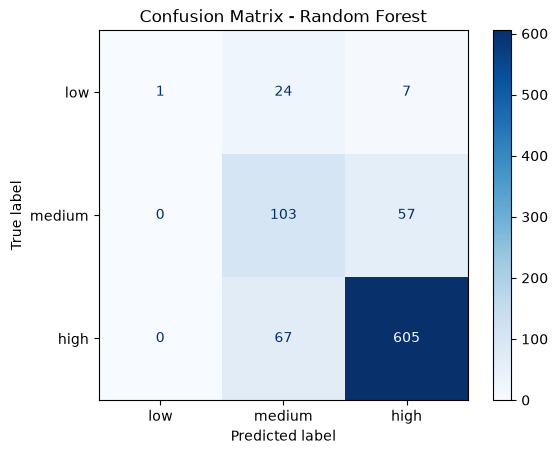

In [447]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_rf, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

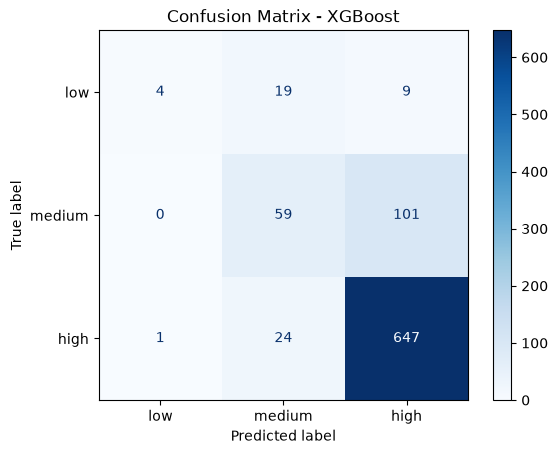

In [448]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_xgb, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - XGBoost')
plt.show()

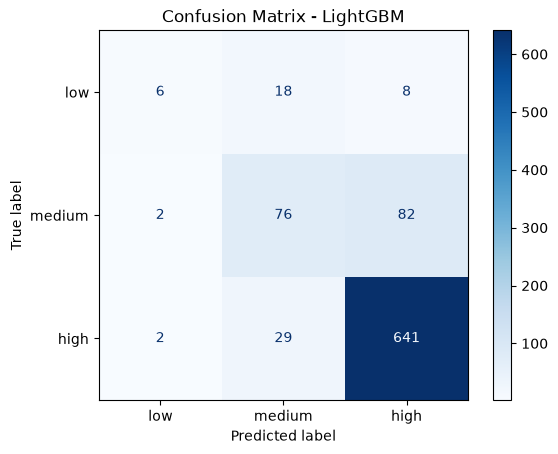

In [449]:
ConfusionMatrixDisplay.from_predictions(y_test_enc, y_pred_lgb, display_labels=label_names, cmap='Blues')
plt.title('Confusion Matrix - LightGBM')
plt.show()